# Orivanta audit analysis

This project uses a fully synthetic dataset created for audit analytics, data analysis, SQL, Python, and Power BI portfolio development. All customers, employees, transactions, conversations, and events are fictional.

I built this notebook as a readable walkthrough of the audit analytics process. The full pipeline runs through `python run_audit.py`; this notebook focuses on the checks, decisions, and results I would talk through in an interview.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Could not locate repository root containing src/')

sys.path.insert(0, str(ROOT / 'src'))
from config import SOURCE_DIR
from data_validation import load_tables, apply_schema
from audit_functions import run_all_tests, calculate_exposure

tables = apply_schema(load_tables(SOURCE_DIR))
print('Repository root:', ROOT.name)
print('Tables loaded:', len(tables))
print('Credits rows:', len(tables['credits_adjustments']))
print('Charges rows:', len(tables['charges']))

Repository root: orivanta-audit-analytics
Tables loaded: 16
Credits rows: 2040
Charges rows: 8515


## Data-quality check

Before testing exceptions, I checked the source structure. One lesson from the project is that identifier handling matters. Account, credit, case, and interaction IDs need to remain strings so joins and groupings do not collapse records.

In [2]:
id_columns = []
for table_name, frame in tables.items():
    for col in frame.columns:
        if col.endswith('_id'):
            id_columns.append((table_name, col, str(frame[col].dtype)))

id_check = pd.DataFrame(id_columns, columns=['table', 'column', 'dtype'])
print(id_check.head(12).to_string(index=False))
print('Non-string ID columns:', len(id_check[~id_check['dtype'].eq('string')]))

            table              column  dtype
        customers         customer_id string
         accounts          account_id string
         accounts         customer_id string
         accounts     service_plan_id string
products_services  product_service_id string
          charges           charge_id string
          charges          account_id string
          charges         customer_id string
          charges  product_service_id string
          charges         location_id string
          charges          invoice_id string
          charges created_by_agent_id string
Non-string ID columns: 0


## Intermediate population check

I used this checkpoint to make sure the main populations were loaded before running any exception logic.

In [3]:
population = pd.DataFrame([
    {'population': 'Customers', 'rows': len(tables['customers'])},
    {'population': 'Accounts', 'rows': len(tables['accounts'])},
    {'population': 'Charges', 'rows': len(tables['charges'])},
    {'population': 'Credits', 'rows': len(tables['credits_adjustments'])},
    {'population': 'Payments', 'rows': len(tables['payments'])},
    {'population': 'Cases', 'rows': len(tables['cases_disputes'])},
    {'population': 'Interactions', 'rows': len(tables['interactions'])},
])
print(population.to_string(index=False))

  population  rows
   Customers  3000
    Accounts  3500
     Charges  8515
     Credits  2040
    Payments  4200
       Cases  1250
Interactions  1300


## Run the audit tests

The project has 40 tests. I keep the full output in the pipeline, but the notebook summarizes what matters most for review.

In [4]:
exceptions, test_summary = run_all_tests(tables)
bridge, deduped, direct, investigative = calculate_exposure(exceptions)
print('Tests:', len(test_summary))
print('Exception/review-lead rows:', len(exceptions))
print(test_summary[['test_id','test_name','rows','severity','confidence']].head(10).to_string(index=False))

Tests: 40
Exception/review-lead rows: 1481
test_id                                  test_name  rows severity confidence
    T01   Credits above authority without approval    32     High       High
    T02                  Missing required approval    31     High       High
    T03            Approval decision after posting    14     High   Moderate
    T04     Approved versus posted amount mismatch    11     High       High
    T05             Credit exceeds original charge   238 Critical       High
    T06                    Exact duplicate credits     5     High       High
    T07                     Near-duplicate credits    32 Moderate   Moderate
    T08 Potential split-credit threshold avoidance    40     High   Moderate
    T09            Invalid or inactive reason code    15 Moderate       High
    T10       Reason code and credit type mismatch     0 Moderate       High


## Rule refinement example

One of the important corrections was removing result-count limits. A test should return every record that meets the documented rule. If a rule returns too many records, the right fix is to refine the business logic, not cap the output.

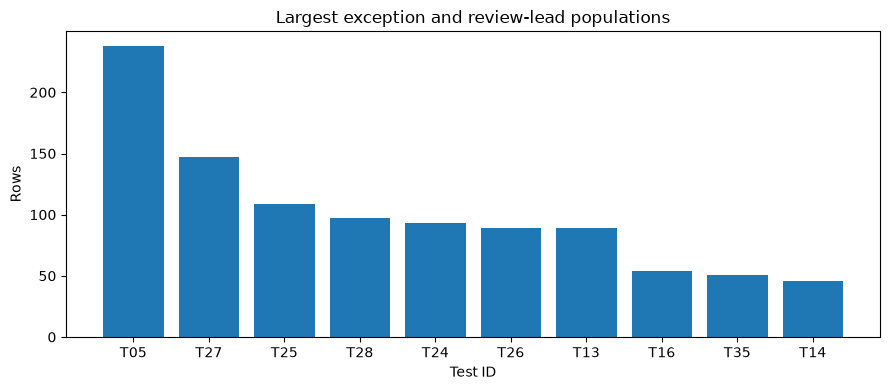

In [5]:
top_tests = test_summary.sort_values('rows', ascending=False).head(10)
plt.figure(figsize=(9, 4))
plt.bar(top_tests['test_id'], top_tests['rows'])
plt.title('Largest exception and review-lead populations')
plt.xlabel('Test ID')
plt.ylabel('Rows')
plt.tight_layout()
plt.show()

## What surprised me

The largest flagged value was not the same as confirmed loss. The exposure bridge was the most important piece of interpretation in the project.

                          exposure_class   amount                                                                        definition
        Gross overlapping flagged amount 60962.90                  Sum of all exception-row flagged amounts before overlap removal.
                         Overlap removed 26381.72 Repeated underlying-record amounts removed using the documented record hierarchy.
Record-level deduplicated flagged amount 34581.18                 Largest flagged amount per underlying record; not confirmed loss.
                Direct measurable amount 14756.86                   Calculable differences only, deduplicated by underlying record.
                    Investigative amount 23139.04                    Transaction value requiring review but not measurable as loss.
                          Confirmed loss     0.00                                     Confirmed financial loss was not established.


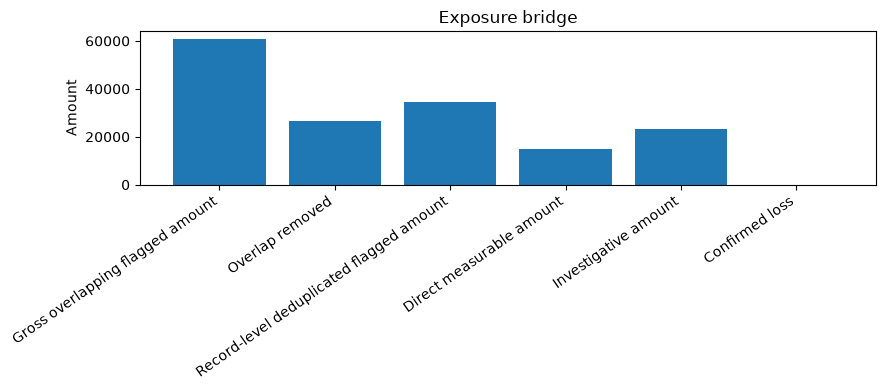

In [6]:
print(bridge.to_string(index=False))
plt.figure(figsize=(9, 4))
plt.bar(bridge['exposure_class'], bridge['amount'])
plt.title('Exposure bridge')
plt.xticks(rotation=35, ha='right')
plt.ylabel('Amount')
plt.tight_layout()
plt.show()

## False-positive discussion

Behavioral and transcript tests are useful for prioritizing review, but they do not prove misconduct. I classified those results more cautiously and added manual review evidence because text rules can over-detect when context is ambiguous.

          exception_class confidence  rows
Behavioral risk indicator        Low    24
Behavioral risk indicator   Moderate    72
        Control exception       High   677
        Control exception   Moderate   348
       Data-quality issue       High    37
       Data-quality issue   Moderate    25
          NLP review lead        Low   298


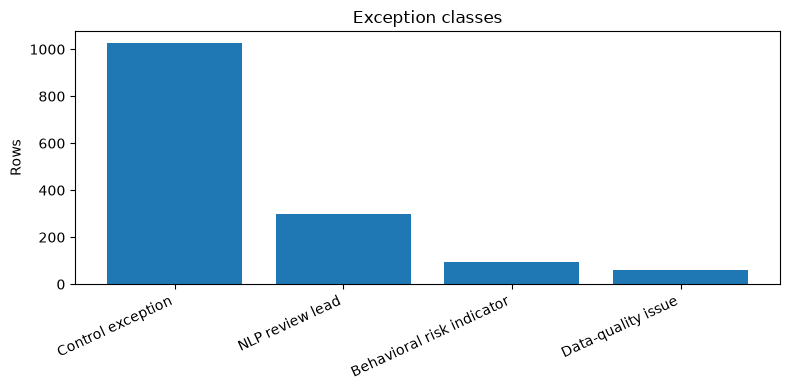

In [7]:
class_summary = exceptions.groupby(['exception_class','confidence']).size().reset_index(name='rows')
print(class_summary.to_string(index=False))
plt.figure(figsize=(8, 4))
class_totals = exceptions.groupby('exception_class').size().sort_values(ascending=False)
plt.bar(class_totals.index, class_totals.values)
plt.title('Exception classes')
plt.xticks(rotation=25, ha='right')
plt.ylabel('Rows')
plt.tight_layout()
plt.show()

## Exposure-classification example

A credit that exceeds the original charge can create a calculable difference. A missing approval is different: it creates a review need, but the full credit amount is not automatically a loss.

In [8]:
examples = exceptions[exceptions['test_id'].isin(['T01','T05','T39'])][['test_id','test_name','record_id','gross_flagged_amount','direct_measurable_amount','investigative_amount']].head(12)
print(examples.to_string(index=False))

test_id                                test_name record_id  gross_flagged_amount  direct_measurable_amount  investigative_amount
    T01 Credits above authority without approval CRD000060                175.00                       0.0                175.00
    T01 Credits above authority without approval CRD000082                175.00                       0.0                175.00
    T01 Credits above authority without approval CRD000365                250.00                       0.0                250.00
    T01 Credits above authority without approval CRD000401                 50.65                       0.0                 50.65
    T01 Credits above authority without approval CRD000439                175.00                       0.0                175.00
    T01 Credits above authority without approval CRD000560                275.00                       0.0                275.00
    T01 Credits above authority without approval CRD000597                150.00                 

## Lessons learned

- Data types can materially change audit conclusions.
- Matching totals is not enough; record-level reconciliation matters.
- Text indicators require cautious language and manual validation.
- Confirmed financial loss was not established.
- The value of the project is not just the exception count; it is the discipline used to interpret the results.